In [1]:
import shutil
import kagglehub
from pathlib import Path
from typing import Dict, List, Optional

def _baixar_e_copiar_dataset(handle: str, dest_dir: Path) -> Path:
    """
    Função auxiliar que baixa um dataset do Kaggle e o copia para o diretório final.
    """
    caminho_cache = kagglehub.dataset_download(handle)

    nome_pasta_destino = handle.replace('/', '_')
    caminho_final = dest_dir / nome_pasta_destino # pathlib facilita a concatenação

    # Limpa o diretório final se ele já existir para evitar arquivos misturados
    if caminho_final.exists():
        shutil.rmtree(caminho_final)

    shutil.copytree(caminho_cache, caminho_final)
    return caminho_final


def get_dados_homologacao(
    diretorio_destino: str = "dados",
    datasets: Optional[List[str]] = None,
    fallbacks: Optional[Dict[str, str]] = None
) -> Dict[str, str]:
    """
    Faz o download e organiza datasets do Kaggle.

    Retorna:
        Um dicionário mapeando o handle do dataset para o caminho salvo (ou mensagem de erro).
    """
    # Define valores padrão caso não sejam passados como argumento
    datasets = datasets or [
        # "adisongoh/it-service-ticket-classification-dataset",
        # "shamiulislamshifat/it-incident-log-dataset",
        "tobiasbueck/multilingual-customer-support-tickets",
        # "ahanwadi/itsm-data",
    ]
    fallbacks = fallbacks or {
        # "ahanwadi/itsm-data": "ahanwahi/itsm-data",
    }

    # Usando pathlib em vez de os.makedirs
    dest_dir = Path(diretorio_destino)
    dest_dir.mkdir(parents=True, exist_ok=True)

    resultados = {}

    # Remove duplicatas preservando a ordem (truque do dict.fromkeys)
    handles_unicos = list(dict.fromkeys(datasets))

    for handle in handles_unicos:
        try:
            caminho_final = _baixar_e_copiar_dataset(handle, dest_dir)
            resultados[handle] = str(caminho_final)
            print(f"OK   | {handle} -> {caminho_final}")

        except Exception as err:
            alt = fallbacks.get(handle)
            if alt:
                try:
                    caminho_final = _baixar_e_copiar_dataset(alt, dest_dir)
                    resultados[alt] = str(caminho_final)
                    print(f"OK   | {alt} (fallback de {handle}) -> {caminho_final}")
                except Exception as err_alt:
                    # Captura o erro do fallback para não travar o loop
                    resultados[alt] = f"ERRO: Fallback falhou - {err_alt}"
                    print(f"ERRO | {alt} (fallback) -> {err_alt}")
            else:
                resultados[handle] = f"ERRO: {err}"
                print(f"ERRO | {handle} -> {err}")

    print("\nResumo:")
    for ds, status in resultados.items():
        print(f"- {ds}: {status}")

    return resultados

# Para chamar a função:
# resultados = get_dados_homologacao()

In [2]:
resultados = get_dados_homologacao()

OK   | tobiasbueck/multilingual-customer-support-tickets -> dados\tobiasbueck_multilingual-customer-support-tickets

Resumo:
- tobiasbueck/multilingual-customer-support-tickets: dados\tobiasbueck_multilingual-customer-support-tickets


In [3]:
import pandas as pd
from pathlib import Path
from typing import List, Optional

itsm_data_path = "dados/tobiasbueck_multilingual-customer-support-tickets/dataset-tickets-multi-lang3-4k.csv"
itsm_data_path2 = "dados/tobiasbueck_multilingual-customer-support-tickets/dataset-tickets-multi-lang-4-20k.csv"

df_itsm_1 = pd.read_csv(itsm_data_path)
df_itsm_2 = pd.read_csv(itsm_data_path2)

In [4]:
#remove linhas onde a descrição do problema é nulla
df_itsm_1 = df_itsm_1.dropna(subset=['body','answer','subject'])
df_itsm_2 = df_itsm_2.dropna(subset=['body','answer','subject'])


In [5]:
print ("INFORMAÇÕES DOS DATASETs")
df_itsm_1.info()
df_itsm_2.info()

print ("DESCRIÇÃO DOS DATASETs")
df_itsm_1.describe()
df_itsm_2.describe()

df_itsm_1.head()
df_itsm_2.head()


INFORMAÇÕES DOS DATASETs
<class 'pandas.DataFrame'>
Index: 3532 entries, 0 to 3999
Data columns (total 17 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   subject        3532 non-null   str    
 1   body           3532 non-null   str    
 2   answer         3532 non-null   str    
 3   type           3532 non-null   str    
 4   queue          3532 non-null   str    
 5   priority       3532 non-null   str    
 6   language       3532 non-null   str    
 7   business_type  3532 non-null   str    
 8   tag_1          3532 non-null   str    
 9   tag_2          3532 non-null   str    
 10  tag_3          3532 non-null   str    
 11  tag_4          3532 non-null   str    
 12  tag_5          3018 non-null   str    
 13  tag_6          1999 non-null   str    
 14  tag_7          961 non-null    str    
 15  tag_8          243 non-null    str    
 16  tag_9          0 non-null      float64
dtypes: float64(1), str(16)
memory usage: 6.4 MB

,subject,body,answer,type,queue,priority,language,tag_1,tag_2,tag_3,tag_4,tag_5,tag_6,tag_7,tag_8
0,Unvorhergesehener Absturz der Datenanalyse-Pla...,Die Datenanalyse-Plattform brach unerwartet ab...,Ich werde Ihnen bei der Lösung des Problems he...,Incident,General Inquiry,low,de,Crash,Technical,Bug,Hardware,Resolution,Outage,Documentation,NaN
1,Customer Support Inquiry,Seeking information on digital strategies that...,We offer a variety of digital strategies and s...,Request,Customer Service,medium,en,Feedback,Sales,IT,Tech Support,NaN,NaN,NaN,NaN
2,Data Analytics for Investment,I am contacting you to request information on ...,I am here to assist you with data analytics to...,Request,Customer Service,medium,en,Technical,Product,Guidance,Documentation,Performance,Feature,NaN,NaN
3,Krankenhaus-Dienstleistung-Problem,Ein Medien-Daten-Sperrverhalten trat aufgrund ...,Zurück zur E-Mail-Beschwerde über den Sperrver...,Incident,Customer Service,high,de,Security,Breach,Login,Maintenance,Incident,Resolution,Feedback,NaN
4,Security,"Dear Customer Support, I am reaching out to in...","Dear [name], we take the security of medical d...",Request,Customer Service,medium,en,Security,Customer,Compliance,Breach,Documentation,Guidance,NaN,NaN


In [6]:
def trata_dados_homologacao(caminhos_arquivos: Optional[List[str]] = None) -> pd.DataFrame:
    """
    Carrega, limpa e unifica arquivos CSV de tickets ITSM.

    Retorna:
        pd.DataFrame: DataFrame processado com as tags consolidadas e colunas selecionadas.
    """

    # get_dados_homologacao()
    # Define os caminhos padrão caso a função seja chamada sem argumentos
    if caminhos_arquivos is None:
        caminhos_arquivos = [
            "dados/tobiasbueck_multilingual-customer-support-tickets/dataset-tickets-multi-lang3-4k.csv",
            "dados/tobiasbueck_multilingual-customer-support-tickets/dataset-tickets-multi-lang-4-20k.csv"
        ]

    dfs_temporarios = []
    colunas_obrigatorias = ['body', 'answer', 'subject']

    # 1. Carregamento iterativo e limpeza antecipada 
    for caminho in caminhos_arquivos:
        if not Path(caminho).exists():
            print(f"AVISO: Arquivo não encontrado e será ignorado -> {caminho}")
            continue

        # Lê o CSV e já descarta as linhas inválidas antes de guardar na lista
        df_temp = pd.read_csv(caminho).dropna(subset=colunas_obrigatorias)
        dfs_temporarios.append(df_temp)

    # Proteção caso nenhum arquivo seja carregado
    if not dfs_temporarios:
        raise ValueError("Nenhum dado pôde ser carregado dos caminhos fornecidos.")

    # 2. Concatenação de todos os DataFrames válidos
    df_itsm = pd.concat(dfs_temporarios, ignore_index=True)

    # 3. Tratamento das colunas de Tag
    colunas_tag = [col for col in df_itsm.columns if col.startswith('tag_') and col != 'tag_9']

    # Otimização: Usar dropna().tolist() nativo é mais performático que lambda com for-loop
    df_itsm['all_tags'] = df_itsm[colunas_tag].apply(lambda row: row.dropna().tolist(), axis=1)

    # 4. Seleção das colunas de interesse
    colunas_finais = ['subject', 'queue', 'body', 'type', 'answer', 'priority', 'all_tags', 'language']
    df_final = df_itsm[colunas_finais]

    print(f"DataFrame processado com sucesso! Total de tickets válidos: {len(df_final)}")

    return df_final

# Exemplo de uso:
# df_tickets = trata_dados_homologacao()
# df_tickets.head()

In [7]:
df_tickets = trata_dados_homologacao()
df_tickets.info()
df_tickets.describe()
df_tickets.head()

DataFrame processado com sucesso! Total de tickets válidos: 22066
<class 'pandas.DataFrame'>
RangeIndex: 22066 entries, 0 to 22065
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   subject   22066 non-null  str   
 1   queue     22066 non-null  str   
 2   body      22066 non-null  str   
 3   type      22066 non-null  str   
 4   answer    22066 non-null  str   
 5   priority  22066 non-null  str   
 6   all_tags  22066 non-null  object
 7   language  22066 non-null  str   
dtypes: object(1), str(7)
memory usage: 22.4+ MB


,subject,queue,body,type,answer,priority,all_tags,language
0,Problema crítico del servidor requiere atenció...,Technical Support,Es necesaria una investigación inmediata sobre...,Incident,Estamos investigando urgentemente el problema ...,high,"[Urgent Issue, Service Disruption, Incident Re...",es
1,Anfrage zur Verfügbarkeit des Dell XPS 13 9310,Customer Service,"Sehr geehrter Kundenservice,\n\nich hoffe, die...",Request,"Sehr geehrter <name>,\n\nvielen Dank, dass Sie...",low,"[Sales Inquiry, Product Support, Customer Serv...",de
2,Erro na Autocompletação de Código do IntelliJ ...,Technical Support,"Prezado Suporte ao Cliente <name>,\n\nEstou es...",Incident,"Prezado <name>,\n\nObrigado por entrar em cont...",high,"[Technical Support, Software Bug, Problem Reso...",pt
3,Urgent Assistance Required: AWS Service,IT Support,"Dear IT Services Support Team, \n\nI am reachi...",Request,"Dear <name>,\n\nThank you for reaching out reg...",high,"[IT Support, Urgent Issue, Service Notificatio...",en
4,Problème d'affichage de MacBook Air,Product Support,Cher équipe de support du magasin en ligne Tec...,Incident,"Cher <name>,\n\nMerci de nous avoir contactés ...",low,"[Technical Support, Product Support, Hardware ...",fr


In [8]:
# Renomeia as colunas para pt-BR e mantém aliases em inglês para não quebrar as células já existentes
mapa_colunas_ptbr = {
    "subject": "assunto",
    "queue": "fila",
    "body": "descricao",
    "type": "tipo",
    "answer": "resposta",
    "priority": "prioridade",
    "all_tags": "todas_tags",
    "language": "idioma",
}

In [9]:
# Renomeia apenas as colunas que ainda estiverem em inglês
colunas_para_renomear = {
    col_en: col_pt
    for col_en, col_pt in mapa_colunas_ptbr.items()
    if col_en in df_tickets.columns
}

df_tickets = df_tickets.rename(columns=colunas_para_renomear)

print(df_tickets.columns.tolist())

['assunto', 'fila', 'descricao', 'tipo', 'resposta', 'prioridade', 'todas_tags', 'idioma']


In [10]:
import pickle

# Salva o dataframe em formato pickle para uso futuro
df_tickets.to_pickle('df_tickets.pkl')

print("DataFrame salvo com sucesso em 'df_tickets.pkl'")

DataFrame salvo com sucesso em 'df_tickets.pkl'


In [33]:
# Salva o DataFrame tratado em CSV
caminho_csv = "df_tickets.csv"
df_tickets.to_csv(caminho_csv, index=False, encoding="utf-8-sig")

print(f"DataFrame salvo com sucesso em '{caminho_csv}'")

DataFrame salvo com sucesso em 'df_tickets.csv'


In [11]:
# # Carrega o dataframe do arquivo pickle
# df_tickets = pd.read_pickle('df_tickets.pkl')

# print("DataFrame carregado com sucesso!")
# print(df_tickets.head())

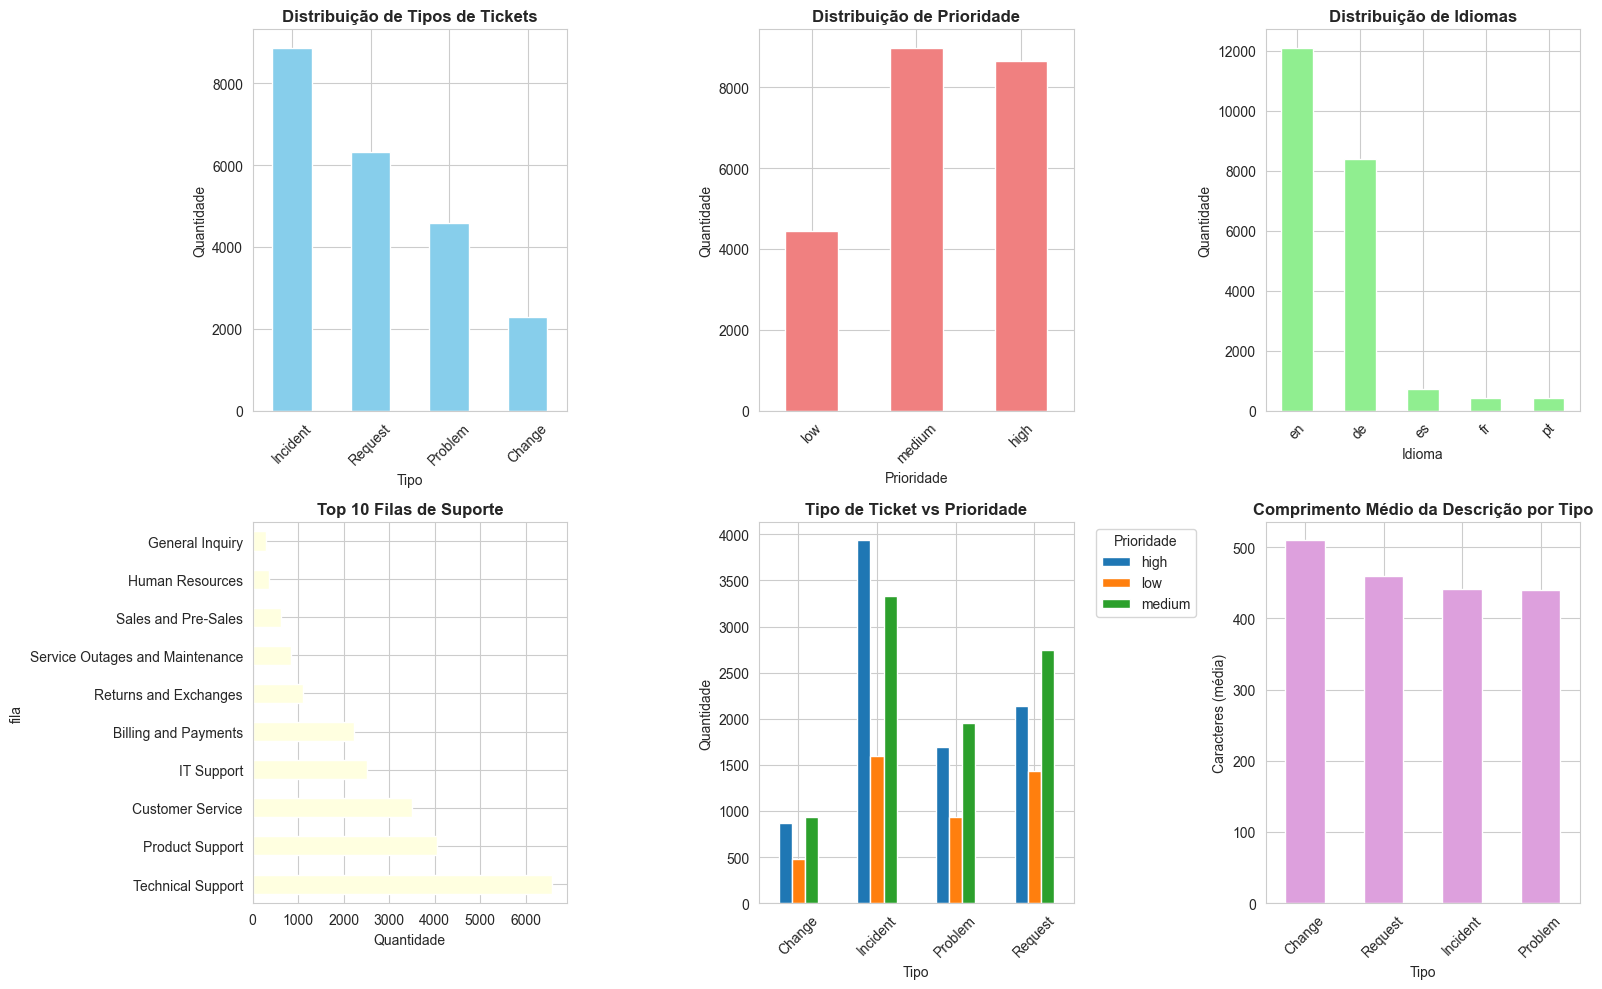

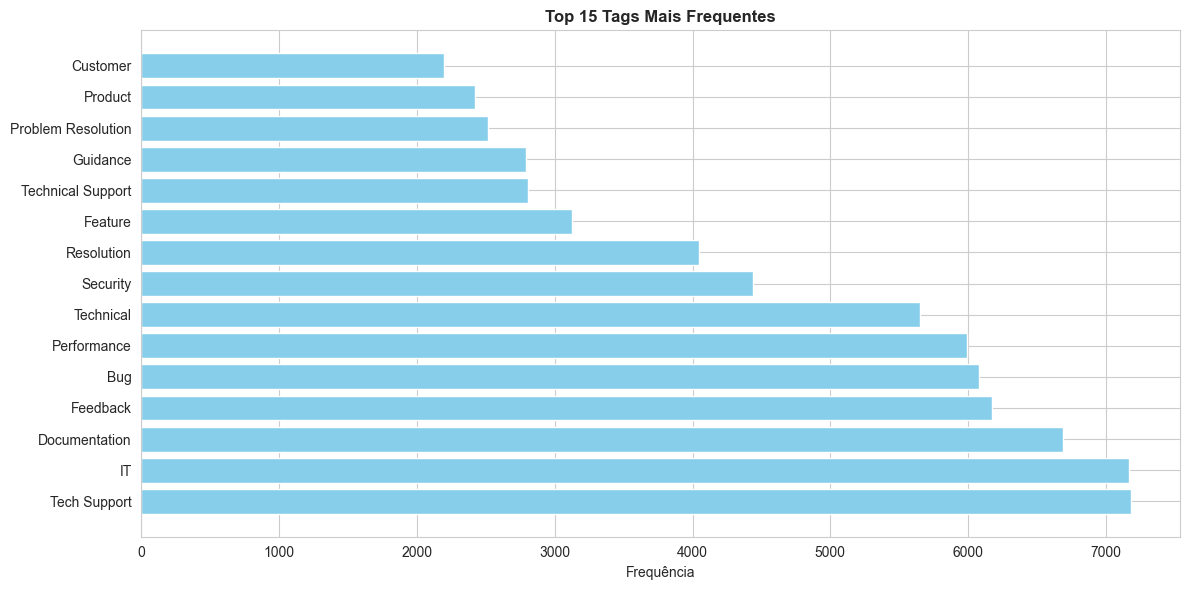


Resumo do Dataset df_tickets:
- Total de tickets: 22066
- Tipos: 4
- Prioridades: 3
- Idiomas: 5
- Filas: 10


In [12]:
import seaborn as sns
from collections import Counter
import numpy as np

import matplotlib.pyplot as plt

# Configurar estilo
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (14, 10)

# 1. Distribuição de Tipos de Tickets
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

ax1 = axes[0, 0]
df_tickets['tipo'].value_counts().plot(kind='bar', ax=ax1, color='skyblue')
ax1.set_title('Distribuição de Tipos de Tickets', fontsize=12, fontweight='bold')
ax1.set_xlabel('Tipo')
ax1.set_ylabel('Quantidade')
ax1.tick_params(axis='x', rotation=45)

# 2. Distribuição de Prioridade
ax2 = axes[0, 1]
priority_order = ['low', 'medium', 'high']
df_tickets['prioridade'].value_counts().reindex(priority_order).plot(kind='bar', ax=ax2, color='lightcoral')
ax2.set_title('Distribuição de Prioridade', fontsize=12, fontweight='bold')
ax2.set_xlabel('Prioridade')
ax2.set_ylabel('Quantidade')
ax2.tick_params(axis='x', rotation=45)

# 3. Distribuição de Idiomas
ax3 = axes[0, 2]
df_tickets['idioma'].value_counts().plot(kind='bar', ax=ax3, color='lightgreen')
ax3.set_title('Distribuição de Idiomas', fontsize=12, fontweight='bold')
ax3.set_xlabel('Idioma')
ax3.set_ylabel('Quantidade')
ax3.tick_params(axis='x', rotation=45)

# 4. Top 10 Filas
ax4 = axes[1, 0]
df_tickets['fila'].value_counts().head(10).plot(kind='barh', ax=ax4, color='lightyellow')
ax4.set_title('Top 10 Filas de Suporte', fontsize=12, fontweight='bold')
ax4.set_xlabel('Quantidade')

# 5. Cruzamento: Tipo vs Prioridade
ax5 = axes[1, 1]
crosstab = pd.crosstab(df_tickets['tipo'], df_tickets['prioridade'])
crosstab.plot(kind='bar', ax=ax5, stacked=False)
ax5.set_title('Tipo de Ticket vs Prioridade', fontsize=12, fontweight='bold')
ax5.set_xlabel('Tipo')
ax5.set_ylabel('Quantidade')
ax5.legend(title='Prioridade', bbox_to_anchor=(1.05, 1), loc='upper left')
ax5.tick_params(axis='x', rotation=45)

# 6. Comprimento médio da descrição por tipo
ax6 = axes[1, 2]
df_tickets['descricao_length'] = df_tickets['descricao'].str.len()
body_length_by_type = df_tickets.groupby('tipo')['descricao_length'].mean().sort_values(ascending=False)
body_length_by_type.plot(kind='bar', ax=ax6, color='plum')
ax6.set_title('Comprimento Médio da Descrição por Tipo', fontsize=12, fontweight='bold')
ax6.set_xlabel('Tipo')
ax6.set_ylabel('Caracteres (média)')
ax6.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

# 7. Tags mais frequentes
all_tags_flat = []
for tags_list in df_tickets['todas_tags']:
    all_tags_flat.extend(tags_list)

top_tags = Counter(all_tags_flat).most_common(15)
tags_names, tags_counts = zip(*top_tags)

fig, ax = plt.subplots(figsize=(12, 6))
ax.barh(tags_names, tags_counts, color='skyblue')
ax.set_title('Top 15 Tags Mais Frequentes', fontsize=12, fontweight='bold')
ax.set_xlabel('Frequência')
plt.tight_layout()
plt.show()

print(f"\nResumo do Dataset df_tickets:")
print(f"- Total de tickets: {len(df_tickets)}")
print(f"- Tipos: {df_tickets['tipo'].nunique()}")
print(f"- Prioridades: {df_tickets['prioridade'].nunique()}")
print(f"- Idiomas: {df_tickets['idioma'].nunique()}")
print(f"- Filas: {df_tickets['fila'].nunique()}")

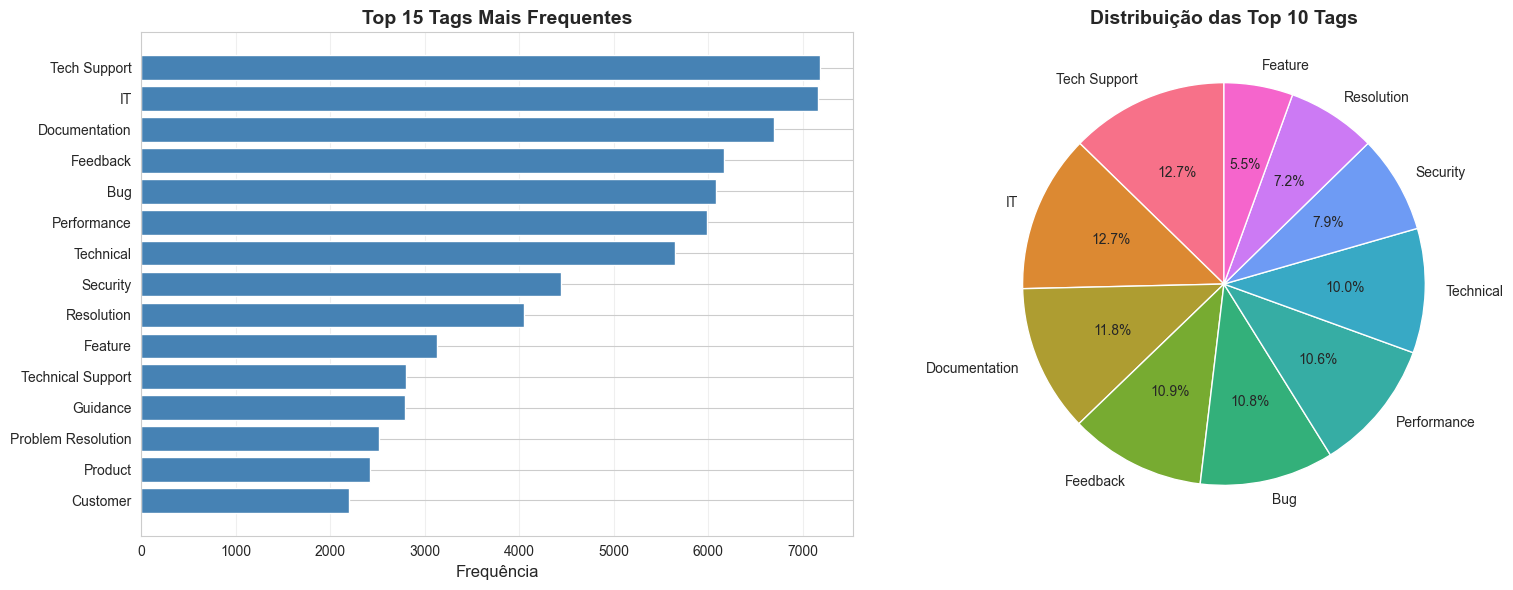


ANÁLISE DETALHADA DE TAGS
Total de tags únicas: 1528
Total de ocorrências de tags: 118092
Média de tags por ticket: 5.35

Top 15 Tags:
 1. Tech Support              |   7179 ocorrências ( 6.08%)
 2. IT                        |   7167 ocorrências ( 6.07%)
 3. Documentation             |   6692 ocorrências ( 5.67%)
 4. Feedback                  |   6171 ocorrências ( 5.23%)
 5. Bug                       |   6080 ocorrências ( 5.15%)
 6. Performance               |   5992 ocorrências ( 5.07%)
 7. Technical                 |   5652 ocorrências ( 4.79%)
 8. Security                  |   4441 ocorrências ( 3.76%)
 9. Resolution                |   4047 ocorrências ( 3.43%)
10. Feature                   |   3129 ocorrências ( 2.65%)
11. Technical Support         |   2803 ocorrências ( 2.37%)
12. Guidance                  |   2794 ocorrências ( 2.37%)
13. Problem Resolution        |   2518 ocorrências ( 2.13%)
14. Product                   |   2418 ocorrências ( 2.05%)
15. Customer            

In [13]:
# Criar visualização das tags com melhor formatação
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Gráfico de barras horizontal - Top 15 Tags
ax1 = axes[0]
ax1.barh(tags_names, tags_counts, color='steelblue')
ax1.set_title('Top 15 Tags Mais Frequentes', fontsize=14, fontweight='bold')
ax1.set_xlabel('Frequência', fontsize=12)
ax1.invert_yaxis()
ax1.grid(axis='x', alpha=0.3)

# 2. Gráfico de pizza - Distribuição das Top 10 Tags
ax2 = axes[1]
top_10_tags = top_tags[:10]
tags_names_10, tags_counts_10 = zip(*top_10_tags)
colors = sns.color_palette('husl', len(tags_names_10))
ax2.pie(tags_counts_10, labels=tags_names_10, autopct='%1.1f%%', colors=colors, startangle=90)
ax2.set_title('Distribuição das Top 10 Tags', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

# Estatísticas adicionais sobre tags
print("\n" + "="*60)
print("ANÁLISE DETALHADA DE TAGS")
print("="*60)
print(f"Total de tags únicas: {len(set(all_tags_flat))}")
print(f"Total de ocorrências de tags: {len(all_tags_flat)}")
print(f"Média de tags por ticket: {len(all_tags_flat) / len(df_tickets):.2f}")
print(f"\nTop 15 Tags:")
for i, (tag, count) in enumerate(top_tags, 1):
    percentage = (count / len(all_tags_flat)) * 100
    print(f"{i:2d}. {tag:<25} | {count:>6} ocorrências ({percentage:>5.2f}%)")

In [14]:
def amostragem_estratificada(
    df,
    colunas_estrato,
    frac: float = None,
    n: int = None,
    min_por_grupo: int = 1,
    random_state: Optional[int] = None,
    replace: bool = False
):
    """
    Realiza amostragem estratificada de um DataFrame.

    Args:
        df: pandas.DataFrame existente (ex.: df_tickets).
        colunas_estrato: str ou list de str com as colunas para estratificar (ex.: 'tipo' ou ['tipo','prioridade']).
        frac: fração a ser amostrada em cada estrato (ex.: 0.1). Use ou `frac` ou `n`.
        n: número fixo de amostras por estrato. Use ou `frac` ou `n`.
        min_por_grupo: mínimo de amostras por grupo quando usar `frac`.
        random_state: semente para reprodutibilidade.
        replace: permite amostragem com reposição (útil quando n > tamanho do grupo).

    Retorna:
        pandas.DataFrame contendo a amostra estratificada.
    """
    if isinstance(colunas_estrato, str):
        colunas_estrato = [colunas_estrato]

    if (frac is None) == (n is None):
        raise ValueError("Forneça exatamente um de: frac ou n.")

    def _sample_por_grupo(g):
        tamanho = len(g)
        if frac is not None:
            k = max(int(round(tamanho * frac)), min_por_grupo)
            k = min(k, tamanho) if not replace else max(k, 1)
        else:
            k = n
            if not replace:
                k = min(k, tamanho)
        return g.sample(n=k, replace=replace, random_state=random_state)

    amostra = df.groupby(colunas_estrato, group_keys=False).apply(_sample_por_grupo)
    # reset index preservando original como necessário
    return amostra.reset_index(drop=True)

# Exemplo de uso:
# amostra1 = amostragem_estratificada(df_tickets, 'prioridade', frac=0.1, random_state=42)
# amostra2 = amostragem_estratificada(df_tickets, ['tipo','prioridade'], n=50, random_state=42, replace=False)